# IRWA Part 1 


This is **our group's original Part 1** with an added export for the existing Part 2 notebook. Run the preprocessing cells through the **Part 2 compatibility export**. The notebook creates `data/fashion_products.csv` and `data/index_info.csv` with the exact names and columns read by the **unchanged** Part 2 indexing notebook. 

In [ ]:
# Load our group's ORIGINAL fashion-products data.
# Prefer JSON because it preserves the structured product_details field.
# If only the raw CSV is available, convert its product_details values back to Python objects.
import json
import ast
from pathlib import Path
import pandas as pd

sources = [
    Path("data/fashion_products_dataset.json"),
    Path("fashion_products_dataset.json"),
    Path("data/fashion_products.csv"),
    Path("fashion_products.csv"),
]
source_path = next((p for p in sources if p.is_file()), None)
if source_path is None:
    raise FileNotFoundError(
        "Put fashion_products_dataset.json (preferred) or the raw fashion_products.csv "
        "inside the data folder."
    )

if source_path.suffix.lower() == ".json":
    with source_path.open("r", encoding="utf-8") as f:
        products = json.load(f)
else:
    source_df = pd.read_csv(source_path)

    def restore_product_details(value):
        if isinstance(value, str):
            try:
                return ast.literal_eval(value)
            except (SyntaxError, ValueError):
                try:
                    return json.loads(value)
                except (json.JSONDecodeError, TypeError):
                    return value
        return [] if pd.isna(value) else value

    if "product_details" in source_df:
        source_df["product_details"] = source_df["product_details"].apply(restore_product_details)
    products = source_df.to_dict("records")

print("Loaded source:", source_path)
print("Data type:", type(products))
print("Number of products:", len(products))
print("Preview:", str(products[0])[:1000])


In [4]:
print("Number of products:", len(products))

print("\nAvailable fields:")
print(list(products[0].keys()))

print("\nExample product:")
for key, value in products[0].items():
    print(f"{key}: {value}")

Number of products: 28080

Available fields:
['_id', 'actual_price', 'average_rating', 'brand', 'category', 'crawled_at', 'description', 'discount', 'images', 'out_of_stock', 'pid', 'product_details', 'seller', 'selling_price', 'sub_category', 'title', 'url']

Example product:
_id: fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a
actual_price: 2,999
average_rating: 3.9
brand: York
category: Clothing and Accessories
crawled_at: 1612987911000
description: Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India
discount: 69% off
images: ['https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/z/y/n/m-1005combo2-yorker-original-imafczg3xfh5qqd4.jpeg?q=70', 'https://rukminim1.flixcart.com/image/128/128/jr58l8w0/track-pant/w/d/a/l-1005combo8-yorker-original-imafczg3pgtxgraq.jpeg?q=70']
out_of_stock: False
pid: TKPFCZ9EA7H5FYZH
product_details: [{'Style Code': '10

In [5]:
#checking if any product are missing any titles, brands or information

import pandas as pd

df = pd.DataFrame(products)

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nUnique product IDs:", df["pid"].nunique())
print("Duplicate product IDs:", df["pid"].duplicated().sum())

Dataset shape: (28080, 17)

Missing values:
_id                0
actual_price       0
average_rating     0
brand              0
category           0
crawled_at         0
description        0
discount           0
images             0
out_of_stock       0
pid                0
product_details    0
seller             0
selling_price      0
sub_category       0
title              0
url                0
dtype: int64

Unique product IDs: 28080
Duplicate product IDs: 0


In [6]:
# Text preprocessing for title and description
# Steps: lowercase -> tokenize/remove punctuation -> remove stopwords -> stem.
# Missing values become empty token lists (not the literal token "nan").

import nltk
import re
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords", quiet=True)

stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def preprocess_text(text):
    if pd.isna(text):
        return []

    text = str(text).lower()
    tokens = re.findall(r"[a-z0-9]+", text)
    tokens = [token for token in tokens if token not in stop_words and len(token) > 1]
    return [stemmer.stem(token) for token in tokens]

df["title_tokens"] = df["title"].apply(preprocess_text)
df["description_tokens"] = df["description"].apply(preprocess_text)

print("Original title:", df["title"].iloc[0])
print("Processed title:", df["title_tokens"].iloc[0])
print("Processed description:", df["description_tokens"].iloc[0])


Original title: Solid Women Multicolor Track Pants
Processed title: ['solid', 'women', 'multicolor', 'track', 'pant']
Processed description: ['yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india']


In [7]:
# Keep a copy of the original product records before preprocessing
df_raw = df.copy()

# Required output schema specified in Part 1
output_fields = [
    "pid",
    "title",
    "description",
    "brand",
    "category",
    "sub_category",
    "product_details",
    "seller",
    "out_of_stock",
    "selling_price",
    "discount",
    "actual_price",
    "average_rating",
    "url"
]

# Check that every required field exists
missing_fields = [
    field for field in output_fields
    if field not in df_raw.columns
]

if missing_fields:
    raise ValueError(f"Missing required output fields: {missing_fields}")

# Select the fields in the required order
output_df = df_raw[output_fields].copy()

# Validate the output
assert output_df.columns.tolist() == output_fields
assert output_df["pid"].equals(df_raw["pid"])

print("Number of output fields:", len(output_df.columns))
print("Number of product records:", len(output_df))
print("Unique product IDs:", output_df["pid"].nunique())

display(output_df.head(3))

Number of output fields: 14
Number of product records: 28080
Unique product IDs: 28080


,pid,title,description,brand,category,sub_category,product_details,seller,out_of_stock,selling_price,discount,actual_price,average_rating,url
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,False,921,69% off,"2,999",3.9,https://www.flipkart.com/yorker-solid-men-mult...
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,False,499,66% off,"1,499",3.9,https://www.flipkart.com/yorker-solid-men-blue...
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,False,931,68% off,"2,999",3.9,https://www.flipkart.com/yorker-solid-men-mult...


In [8]:
# Keep categorical fields separate for future field-specific ranking.
# Flatten product_details into searchable text while retaining the original field.
def flatten_details(details):
    if isinstance(details, list):
        parts = []
        for item in details:
            if isinstance(item, dict):
                parts.extend(f"{key} {value}" for key, value in item.items()
                             if not pd.isna(value))
        return " ".join(parts)
    if isinstance(details, dict):
        return " ".join(f"{key} {value}" for key, value in details.items()
                        if not pd.isna(value))
    return "" if pd.isna(details) else str(details)

df["product_details_text"] = df["product_details"].apply(flatten_details)

for field in ["category", "sub_category", "product_details_text"]:
    df[field + "_tokens"] = df[field].apply(preprocess_text)

# Brand and seller are identifiers/categories: normalize case and whitespace,
# but do not stem them (stemming can distort proper names).
for field in ["brand", "seller"]:
    df[field + "_normalized"] = df[field].apply(
        lambda value: "" if pd.isna(value) else str(value).strip().lower()
    )
    df[field + "_tokens"] = df[field].apply(
        lambda value: re.findall(r"[a-z0-9]+", "" if pd.isna(value) else str(value).lower())
    )

for field in ["category", "sub_category", "brand", "seller", "product_details_text"]:
    print(f"{field} tokens:", df[field + "_tokens"].iloc[0])


category tokens: ['cloth', 'accessori']
sub_category tokens: ['bottomwear']
brand tokens: ['york']
seller tokens: ['shyam', 'enterprises']
product_details_text tokens: ['style', 'code', '1005combo2', 'closur', 'elast', 'pocket', 'side', 'pocket', 'fabric', 'cotton', 'blend', 'pattern', 'solid', 'color', 'multicolor']


In [9]:
# Numeric and Boolean attributes should remain structured metadata,
# rather than being mixed into the ordinary text index.

def parse_numeric(value):
    if pd.isna(value):
        return float("nan")
    cleaned = re.sub(r"[^0-9.]", "", str(value).replace(",", ""))
    return pd.to_numeric(cleaned, errors="coerce") if cleaned else float("nan")

for field in ["selling_price", "actual_price", "average_rating"]:
    df[field + "_num"] = df[field].apply(parse_numeric)

df["discount_pct"] = df["discount"].apply(parse_numeric)

def parse_bool(value):
    if isinstance(value, bool):
        return value
    if pd.isna(value):
        return pd.NA
    normalized = str(value).strip().lower()
    if normalized in {"true", "1", "yes", "y"}:
        return True
    if normalized in {"false", "0", "no", "n"}:
        return False
    return pd.NA

df["out_of_stock_bool"] = df["out_of_stock"].apply(parse_bool).astype("boolean")

numeric_and_boolean = [
    "selling_price_num", "actual_price_num", "average_rating_num",
    "discount_pct", "out_of_stock_bool"
]
display(df[numeric_and_boolean].head())
print("\nMissing values after conversion:")
print(df[numeric_and_boolean].isna().sum())


,selling_price_num,actual_price_num,average_rating_num,discount_pct,out_of_stock_bool
0,921.0,2999.0,3.9,69.0,False
1,499.0,1499.0,3.9,66.0,False
2,931.0,2999.0,3.9,68.0,False
3,911.0,2999.0,3.9,69.0,False
4,943.0,2999.0,3.9,68.0,False



Missing values after conversion:
selling_price_num        2
actual_price_num       777
average_rating_num    2261
discount_pct           855
out_of_stock_bool        0
dtype: int64


### Export Part 1 for the unchanged Part 2 notebook

The original Part 2 notebook loads `data/fashion_products.csv` and `data/index_info.csv`. This cell exports **our own Part 1 preprocessing** using those exact filenames and the required eight index columns. Brand and seller tokens are stemmed *only in the compatibility export* to align with Part 2 query stemming. The original Part 1 fields remain intact.


In [ ]:
# Export our group's actual Part 1 preprocessing in the exact format
# expected by the ORIGINAL Part 2 indexing notebook (no Part 2 edits needed).
from pathlib import Path

output_dir = Path("data")
output_dir.mkdir(parents=True, exist_ok=True)

required_output_fields = [
    "pid", "title", "description", "brand", "category", "sub_category",
    "product_details", "seller", "out_of_stock", "selling_price",
    "discount", "actual_price", "average_rating", "url"
]
missing_required = [field for field in required_output_fields if field not in df.columns]
if missing_required:
    raise ValueError(f"Dataset is missing required fields: {missing_required}")

# Original product metadata (for titles, brand names and product ID lookup).
processed_output = df[required_output_fields].copy()

# The group's own tokenized fields, converted into Part 2's required names.
# Part 2 already applies Porter stemming to user queries, so stem the brand
# and seller tokens in this COMPATIBILITY EXPORT only; the group's own
# brand_tokens and seller_tokens remain unchanged in the Part 1 notebook.
index_info = pd.DataFrame({
    "pid": df["pid"],
    "title": df["title_tokens"],
    "description": df["description_tokens"],
    "brand": df["brand_tokens"].apply(
        lambda tokens: [stemmer.stem(token) for token in tokens]
    ),
    "category": df["category_tokens"],
    "sub_category": df["sub_category_tokens"],
    "seller": df["seller_tokens"].apply(
        lambda tokens: [stemmer.stem(token) for token in tokens]
    ),
    "product_details": df["product_details_text_tokens"],
})

assert len(processed_output) == len(index_info)
assert processed_output["pid"].equals(index_info["pid"])
assert processed_output["pid"].is_unique
assert index_info.drop(columns="pid").map(lambda x: isinstance(x, list)).all().all()

# REQUIRED BY THE ORIGINAL PART 2 — use these unchanged file names.
processed_output.to_csv(output_dir / "fashion_products.csv", index=False)
index_info.to_csv(output_dir / "index_info.csv", index=False)

# Also keep the JSON exports produced by our group's Part 1.
search_columns = [
    "pid", "title_tokens", "description_tokens",
    "category_tokens", "sub_category_tokens",
    "brand_normalized", "brand_tokens",
    "seller_normalized", "seller_tokens",
    "product_details_text", "product_details_text_tokens",
    "selling_price_num", "actual_price_num", "discount_pct",
    "average_rating_num", "out_of_stock_bool"
]
search_columns = [column for column in search_columns if column in df.columns]
search_index_data = df[search_columns].copy()

processed_output.to_json(output_dir / "part1_processed_products.json",
                         orient="records", force_ascii=False, indent=2)
search_index_data.to_json(output_dir / "part1_search_fields.json",
                          orient="records", force_ascii=False, indent=2)

print("Part 1 validation completed.")
print("Products:", len(df))
print("Unique PIDs:", df["pid"].nunique())
print("Part 2-ready original data:", output_dir / "fashion_products.csv", processed_output.shape)
print("Part 2-ready token data:", output_dir / "index_info.csv", index_info.shape)
print("Part 2 notebook can be run WITHOUT changes.")


In [10]:
original_fields = {
    "selling_price": "selling_price_num",
    "actual_price": "actual_price_num",
    "average_rating": "average_rating_num",
    "discount": "discount_pct",
    "out_of_stock": "out_of_stock_bool"
}

for original, converted in original_fields.items():
    print(f"\n--- {original} ---")
    print("Missing in original:", df[original].isna().sum())
    print("Missing after conversion:", df[converted].isna().sum())

    # Show examples where a value existed originally but conversion failed
    failed = df[df[original].notna() & df[converted].isna()]
    print("Non-missing original values that failed:", len(failed))
    print(failed[original].head(10).tolist())


--- selling_price ---
Missing in original: 0
Missing after conversion: 2
Non-missing original values that failed: 2
['', '']

--- actual_price ---
Missing in original: 0
Missing after conversion: 777
Non-missing original values that failed: 777
['', '', '', '', '', '', '', '', '', '']

--- average_rating ---
Missing in original: 0
Missing after conversion: 2261
Non-missing original values that failed: 2261
['', '', '', '', '', '', '', '', '', '']

--- discount ---
Missing in original: 0
Missing after conversion: 855
Non-missing original values that failed: 855
['', '', '', '', '', '', '', '', '', '']

--- out_of_stock ---
Missing in original: 0
Missing after conversion: 0
Non-missing original values that failed: 0
[]


In [11]:

#weren't converted because they may contain non numeric information or placeholders.These values would be replaced with NAN without further investigation

fields = {
    "selling_price": "selling_price_num",
    "actual_price": "actual_price_num",
    "average_rating": "average_rating_num",
    "discount": "discount_pct"
}

for original, converted in fields.items():
    print(f"\n--- {original.upper()} ---")

    invalid = df.loc[df[converted].isna(), original]

    print("Unconverted values:", len(invalid))
    print("Original values and frequencies:")
    print(invalid.value_counts(dropna=False).head(10))

    # okay so some numerical fields contain empty strings instead of numbers.
    #And so these missing values here should be kept as NAN so we don't introduce
    #incorrect information into our analysis.



--- SELLING_PRICE ---
Unconverted values: 2
Original values and frequencies:
selling_price
    2
Name: count, dtype: int64

--- ACTUAL_PRICE ---
Unconverted values: 777
Original values and frequencies:
actual_price
    777
Name: count, dtype: int64

--- AVERAGE_RATING ---
Unconverted values: 2261
Original values and frequencies:
average_rating
    2261
Name: count, dtype: int64

--- DISCOUNT ---
Unconverted values: 855
Original values and frequencies:
discount
    855
Name: count, dtype: int64


In [12]:
#We start the exploratory data analysis EDA:
# Basic statistics for numerical attributes

columns = [
    "selling_price_num",
    "actual_price_num",
    "average_rating_num",
    "discount_pct"
]

print("Summary statistics:")
print(df[columns].describe().round(2))



Summary statistics:
       selling_price_num  actual_price_num  average_rating_num  discount_pct
count           28078.00          27303.00            25819.00      27225.00
mean              705.64           1455.53                3.63         50.26
std               549.68            939.98                0.66         16.89
min                99.00            150.00                1.00          1.00
25%               390.00            849.00                3.20         40.00
50%               545.00           1199.00                3.80         53.00
75%               820.00           1799.00                4.10         63.00
max              7999.00          12999.00                5.00         87.00


### Interpretation note\n
Use the summary statistics above to describe the actual dataset. Do not copy fixed values from an earlier run: the values depend on the dataset version and on successful numeric conversion.\n

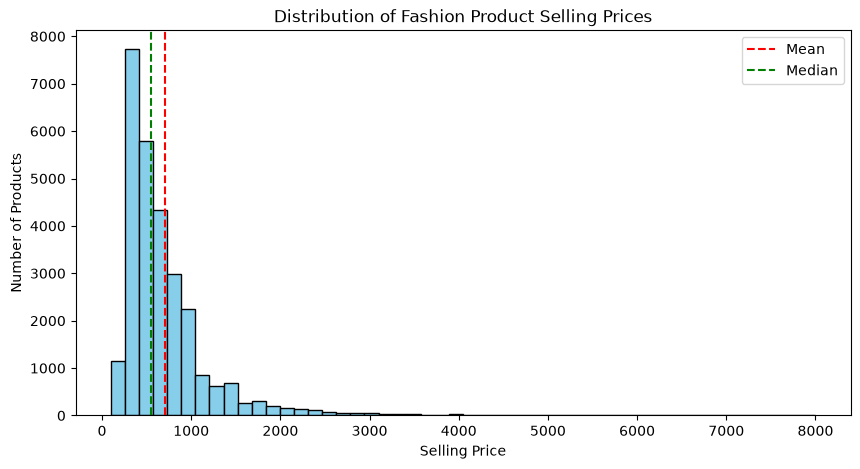

In [13]:
#Now we will create the first visualization:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df["selling_price_num"].dropna(),
    bins=50,
    color="skyblue",
    edgecolor="black"
)

plt.title("Distribution of Fashion Product Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Products")

plt.axvline(
    df["selling_price_num"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

plt.axvline(
    df["selling_price_num"].median(),
    color="green",
    linestyle="--",
    label="Median"
)

plt.legend()
plt.show()

### Interpretation note\n
Describe the observed shape of the selling-price histogram. Compare its mean and median and mention that missing/unparseable prices are excluded.\n

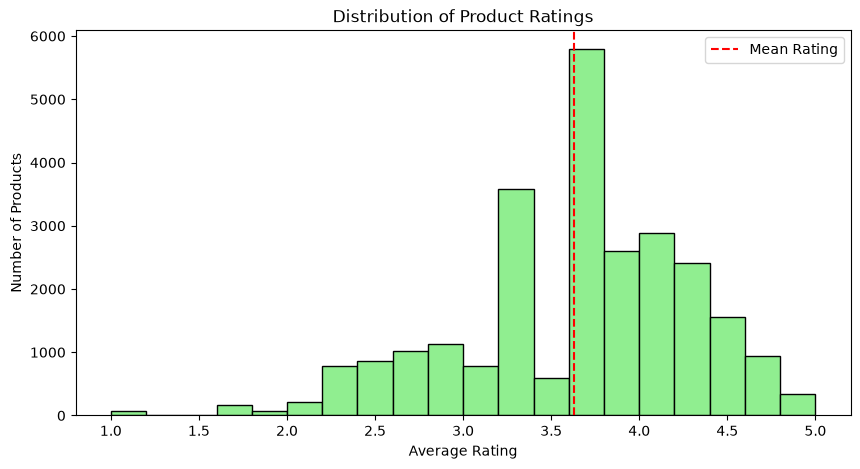

In [14]:
#Now we analyze the product ratings:
plt.figure(figsize=(10, 5))

plt.hist(
    df["average_rating_num"].dropna(),
    bins=20,
    color="lightgreen",
    edgecolor="black"
)

plt.title("Distribution of Product Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Products")

plt.axvline(
    df["average_rating_num"].mean(),
    color="red",
    linestyle="--",
    label="Mean Rating"
)

plt.legend()
plt.show()

### Interpretation note\n
Describe the observed rating distribution using the chart and summary statistics. Missing or unparseable ratings are excluded.\n

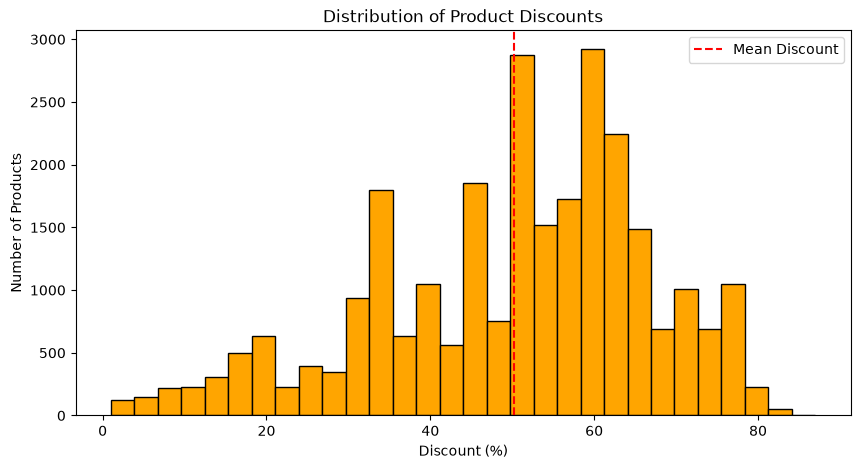

In [15]:
#Now we will analyze the discount distribution:
plt.figure(figsize=(10, 5))

plt.hist(
    df["discount_pct"].dropna(),
    bins=30,
    color="orange",
    edgecolor="black"
)

plt.title("Distribution of Product Discounts")
plt.xlabel("Discount (%)")
plt.ylabel("Number of Products")

plt.axvline(
    df["discount_pct"].mean(),
    color="red",
    linestyle="--",
    label="Mean Discount"
)

plt.legend()
plt.show()

### Interpretation note\n
Describe the observed discount distribution. Missing or unparseable discounts are excluded.\n

In [16]:
# ============================================================
# 1. IMPORTS AND PREPARATION
# ============================================================

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Use a copy to preserve the original DataFrame
eda = df.copy()

def safe_text(value):
    """Convert a non-missing value to text."""
    return "" if pd.isna(value) else str(value)

# Create a combined text field for general word statistics
text_fields = [c for c in ["title", "description"] if c in eda.columns]

eda["eda_text"] = eda[text_fields].apply(
    lambda row: " ".join(safe_text(x) for x in row),
    axis=1
)

def tokenize(text):
    """Lowercase text and extract alphanumeric tokens."""
    return re.findall(r"\b[a-z0-9]+\b", safe_text(text).lower())

eda["eda_tokens"] = eda["eda_text"].map(tokenize)
eda["word_count"] = eda["eda_tokens"].map(len)

# Use the numeric columns created during Exercise 4.
# If they do not exist, create them from the original fields.
for original, processed in [
    ("selling_price", "selling_price_num"),
    ("actual_price", "actual_price_num"),
    ("average_rating", "average_rating_num"),
]:
    if processed not in eda.columns and original in eda.columns:
        cleaned = (
            eda[original].astype("string")
            .str.replace(",", "", regex=False)
            .str.replace(r"[^\d.]", "", regex=True)
        )
        eda[processed] = pd.to_numeric(cleaned, errors="coerce")

if "discount_pct" not in eda.columns and "discount" in eda.columns:
    discount = eda["discount"].astype("string").str.extract(
        r"(\d+(?:\.\d+)?)", expand=False
    )
    eda["discount_pct"] = pd.to_numeric(discount, errors="coerce")

if "out_of_stock_bool" not in eda.columns and "out_of_stock" in eda.columns:
    eda["out_of_stock_bool"] = (
        eda["out_of_stock"].astype("string").str.strip().str.lower()
        .map({"true": True, "false": False})
    )

# Use pid as the product identifier, where available
if "pid" not in eda.columns:
    eda["pid"] = eda.index.astype(str)

print("Number of products:", len(eda))
print("Text fields used:", text_fields)
print("Average words per product:", round(eda["word_count"].mean(), 2))

Number of products: 28080
Text fields used: ['title', 'description']
Average words per product: 37.6



Word-count statistics:
count    28080.000000
mean        37.604345
std         46.313968
min          1.000000
25%          7.000000
50%         18.000000
75%         57.000000
max        702.000000
Name: word_count, dtype: float64


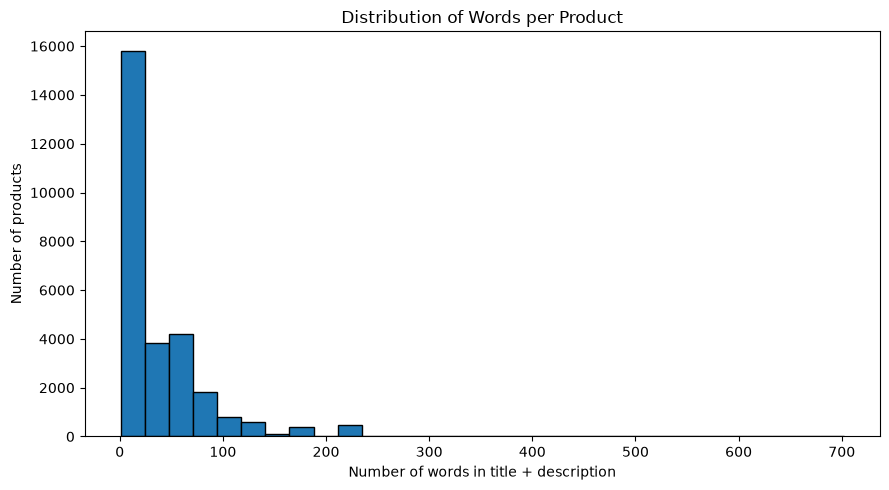

C:\Users\guill\AppData\Local\Temp\ipykernel_16436\3686357180.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(eda["word_count"].dropna(), vert=False)


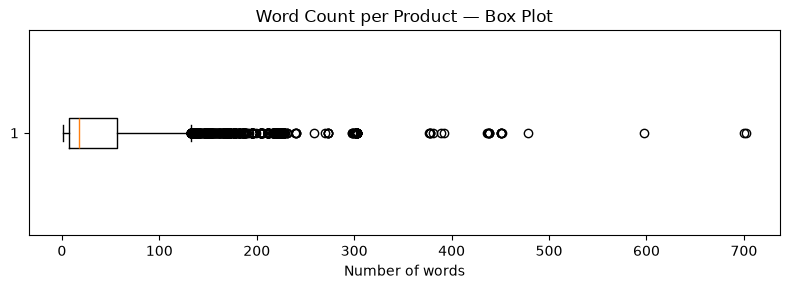

In [17]:
# ============================================================
# 2. WORD-COUNT DISTRIBUTION
# ============================================================

print("\nWord-count statistics:")
print(eda["word_count"].describe())

plt.figure(figsize=(9, 5))
plt.hist(eda["word_count"], bins=30, edgecolor="black")
plt.title("Distribution of Words per Product")
plt.xlabel("Number of words in title + description")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()

# Optional: box plot to identify unusually long documents
plt.figure(figsize=(8, 3))
plt.boxplot(eda["word_count"].dropna(), vert=False)
plt.title("Word Count per Product — Box Plot")
plt.xlabel("Number of words")
plt.tight_layout()
plt.show()

Number of detected sentences: 56512
Average sentence length (words): 15.24
Median sentence length (words): 14.0


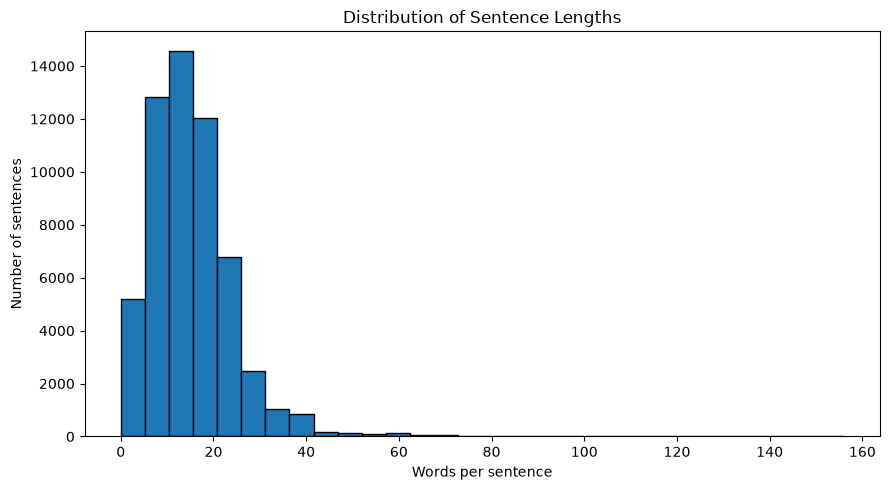

In [18]:
# ============================================================
# 3. AVERAGE SENTENCE LENGTH
# ============================================================

sentence_source = (
    eda["description"].map(safe_text)
    if "description" in eda.columns
    else eda["eda_text"].map(safe_text)
)

def split_sentences(text):
    """Approximate sentence splitting using terminal punctuation."""
    text = safe_text(text).strip()
    if not text:
        return []
    return [
        sentence.strip()
        for sentence in re.split(r"[.!?]+", text)
        if sentence.strip()
    ]

def sentence_lengths(text):
    """Return word counts for the sentences in one description."""
    lengths = []
    for sentence in split_sentences(text):
        lengths.append(len(tokenize(sentence)))
    return lengths

all_sentence_lengths = [
    length
    for text in sentence_source
    for length in sentence_lengths(text)
]

if all_sentence_lengths:
    print("Number of detected sentences:", len(all_sentence_lengths))
    print("Average sentence length (words):",
          round(np.mean(all_sentence_lengths), 2))
    print("Median sentence length (words):",
          round(np.median(all_sentence_lengths), 2))

    plt.figure(figsize=(9, 5))
    plt.hist(all_sentence_lengths, bins=30, edgecolor="black")
    plt.title("Distribution of Sentence Lengths")
    plt.xlabel("Words per sentence")
    plt.ylabel("Number of sentences")
    plt.tight_layout()
    plt.show()
else:
    print("No sentences were available for analysis.")

Total number of tokens: 1055930
Vocabulary size (unique tokens): 6495
Top 20 most frequent tokens:
  word  frequency
   and      31264
 shirt      28217
     t      26798
   the      23361
   for      19832
     a      19652
    of      19486
 women      17058
   men      16259
  with      15550
    to      15155
  neck      14943
   you      13964
  this      13217
    is      12504
cotton      11793
    in      11431
    it      10742
 solid      10558
 round      10190


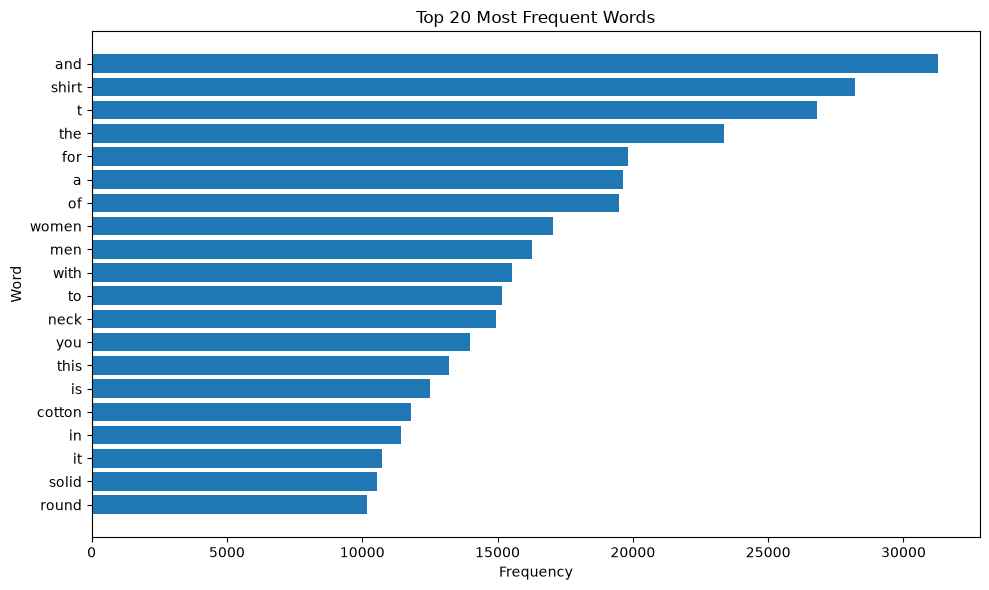

In [19]:
# ============================================================
# 4. VOCABULARY SIZE AND WORD FREQUENCIES
# ============================================================

all_tokens = [
    token
    for tokens in eda["eda_tokens"]
    for token in tokens
]

vocabulary = set(all_tokens)
word_frequencies = Counter(all_tokens)

print("Total number of tokens:", len(all_tokens))
print("Vocabulary size (unique tokens):", len(vocabulary))
print("Top 20 most frequent tokens:")
print(pd.DataFrame(
    word_frequencies.most_common(20),
    columns=["word", "frequency"]
).to_string(index=False))

top_words = pd.DataFrame(
    word_frequencies.most_common(20),
    columns=["word", "frequency"]
)

plt.figure(figsize=(10, 6))
plt.barh(top_words["word"][::-1], top_words["frequency"][::-1])
plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

## Additional exploratory analyses\n
The following sections extend the EDA with the product, brand, seller and stock summaries suggested in the Part 1 brief.


Top 10 brands:


,product_count
brand,
ECKO Unl,951
Free Authori,860
ARBO,806
REEB,802
Pu,798
True Bl,793
Keo,660
Amp,585
Black Beat,548


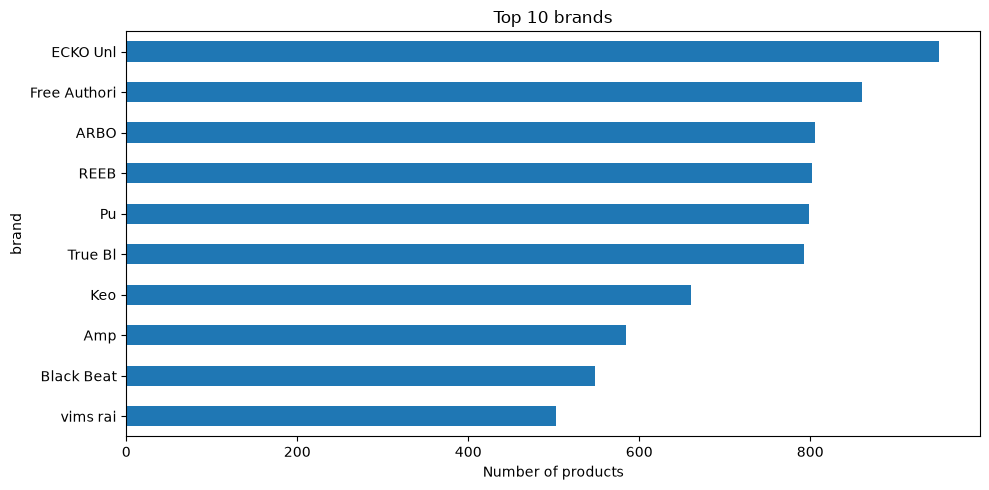


Top 10 sellers:


,product_count
seller,
RetailNet,1411
SandSMarketing,887
BioworldMerchandising,842
ARBOR,783
Keoti,660
AFFGARMENTS,587
Black Beatle,548
AMALGUS ENTERPRISE,477
Tayab Manch Fashions,436


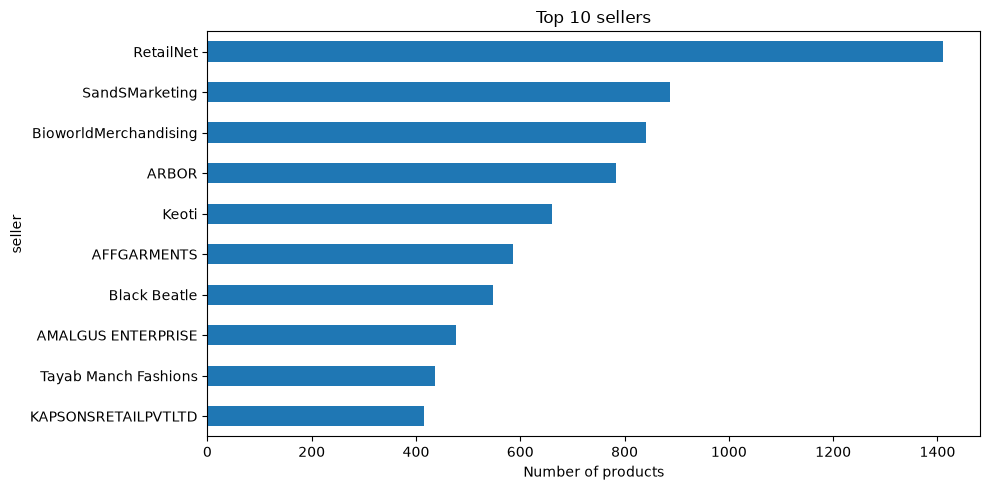

In [20]:
# Top brands and sellers
for field, title in [("brand", "Top 10 brands"), ("seller", "Top 10 sellers")]:
    if field in df.columns:
        counts = df[field].dropna().astype(str).str.strip()
        counts = counts[counts.ne("")].value_counts().head(10)
        print(f"\n{title}:")
        display(counts.rename("product_count").to_frame())

        if not counts.empty:
            plt.figure(figsize=(10, 5))
            counts.sort_values().plot(kind="barh")
            plt.title(title)
            plt.xlabel("Number of products")
            plt.tight_layout()
            plt.show()


Stock availability counts (True = out of stock):


,product_count
out_of_stock_bool,
False,26436
True,1644


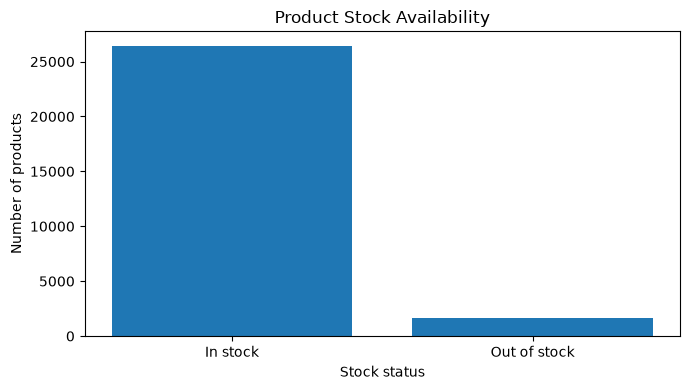

In [22]:

# Product stock availability

stock_counts = df["out_of_stock_bool"].value_counts(dropna=False)

print("Stock availability counts (True = out of stock):")
display(stock_counts.rename("product_count").to_frame())

# Create readable labels for the chart
labels = []

for status in stock_counts.index:
    if pd.isna(status):
        labels.append("Unknown")
    elif bool(status):
        labels.append("Out of stock")
    else:
        labels.append("In stock")

# Plot numerical counts with readable labels
plt.figure(figsize=(7, 4))

plt.bar(labels, stock_counts.values)

plt.title("Product Stock Availability")
plt.xlabel("Stock status")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()


In [23]:
# Top-rated products (ratings are not a measure of relevance; this is descriptive EDA)
top_rated = (
    df.dropna(subset=["average_rating_num"])
      .sort_values(["average_rating_num", "pid"], ascending=[False, True])
      [["pid", "title", "brand", "average_rating_num"]]
      .head(10)
)
display(top_rated)


,pid,title,brand,average_rating_num
8241,BRFFEW85MY5GKHKY,Women Brief (Pack of 4),V,5.0
13242,BRFFFEH4B6JVT5A5,Men Brief (Pack of 5),VIKING.INE,5.0
13240,BRFFFYHUQGBFXZTG,Men Brief (Pack of 5),VIKING.INE,5.0
22361,BRFFM8J3XCQHKYYA,Men Brief (Pack of 5),COL,5.0
8063,BRFFV7H5ZRDZUSTG,Women Brief (Pack of 6),V,5.0
15554,BXRFGGZKHS3GH2XJ,Printed Women Boxer (Pack of 1),Urban D,5.0
417,BXRFGYUGJCWWZ7UG,Printed Men Boxer (Pack of 1),SayItLo,5.0
443,BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),SayItLo,5.0
3324,BXRFN4R5J8YGQ9ZV,Printed Men Boxer (Pack of 2),MagMatri,5.0
13195,BXRFZ5JFGBTNSYXG,Printed Women Boxer (Pack of 2),K,5.0


In [24]:
# Most common categories and subcategories
for field in ["category", "sub_category"]:
    if field in df.columns:
        print(f"\nTop 10 {field} values:")
        display(df[field].dropna().astype(str).value_counts().head(10).rename("product_count").to_frame())



Top 10 category values:


,product_count
category,
Clothing and Accessories,27118
Footwear,920
"Bags, Wallets & Belts",41
Toys,1



Top 10 sub_category values:


,product_count
sub_category,
Topwear,15310
Bottomwear,3666
Winter Wear,2493
Innerwear and Swimwear,1762
Clothing Accessories,1742
"Kurtas, Ethnic Sets and Bottoms",1180
Men's Footwear,920
Fabrics,534
Sleepwear,122


## Preprocessing decisions for the report\n
- **Title and description:** lowercase, alphanumeric tokenization (which removes punctuation), English stop-word removal, and Porter stemming. These are the principal free-text fields.\n
- **Category and sub-category:** retain as separate fields and create token columns. Their controlled, distinctive values can be used as field-specific evidence in later ranking.\n
- **Brand and seller:** retain as separate categorical fields; normalize case and whitespace but do not stem proper names. Separate fields allow exact/category-aware matching and avoid blending seller/brand terms into general prose.\n
- **Product details:** flatten key-value pairs into a searchable text representation and tokenize it, while preserving the original `product_details` for display.\n
- **Prices, discount, rating and stock:** retain as structured numeric/Boolean metadata, not ordinary text terms. This supports filters, sorting and range conditions. Missing or unparseable values remain missing rather than being guessed.\n
- **PID and URL:** preserve unchanged. PID is required for evaluation and URL is needed to link back to the product.\n
\n**Trade-off:** merging every field into one text string is simple but loses field identity and makes field-specific weighting/filtering harder. Separate fields require a more capable index, but preserve distinctions and support better ranking control. The two validation queries in the brief also suggest that gender, garment type, fit, colour and material terms should remain discoverable in their original fields.